In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# STEP 1: IMPORT LIBRARIES

In [ ]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
%pip install -q xgboost

#STEP 2 - DATA COLLECTION

In [ ]:
zip_path = '/content/drive/MyDrive/StudentPerformanceFactors.zip'
extract_path = '/content/StudentPerformanceFactors'

# Extract ZIP file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

    print("ZIP file extracted successfully!\n")

    # Find CSV file inside extracted folder
    csv_file = None

    for root, dirs, files in os.walk(extract_path):
        for file in files:
            if file.endswith('.csv'):
                csv_file = os.path.join(root, file)
                break # Corrected indentation for break
        if csv_file: # If CSV file is found in the current root, no need to search further
            break

    # Load CSV only if csv_file was found
    if csv_file:
        df = pd.read_csv(csv_file)

        print("Dataset loaded successfully!\n")
        print("CSV file:", csv_file)
        print("\nDataset dimension:", df.shape)

        display(df.head())
    else:
        print("No CSV file found in the extracted directory.")

ZIP file extracted successfully!

Dataset loaded successfully!

CSV file: /content/StudentPerformanceFactors/StudentPerformanceFactors.csv

Dataset dimension: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


#STEP 3 - INITIAL DATA INSPECTION

Display the first and last records

In [ ]:
print("FIRST 5 ROWS")
display(df.head())

print("\nLAST 5 ROWS")
display(df.tail())

FIRST 5 ROWS


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



LAST 5 ROWS


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


Dataset dimensions

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6607
Number of columns: 20


Column names

In [ ]:
print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(i, "-", column)

Column names:
1 - Hours_Studied
2 - Attendance
3 - Parental_Involvement
4 - Access_to_Resources
5 - Extracurricular_Activities
6 - Sleep_Hours
7 - Previous_Scores
8 - Motivation_Level
9 - Internet_Access
10 - Tutoring_Sessions
11 - Family_Income
12 - Teacher_Quality
13 - School_Type
14 - Peer_Influence
15 - Physical_Activity
16 - Learning_Disabilities
17 - Parental_Education_Level
18 - Distance_from_Home
19 - Gender
20 - Exam_Score


Data types and information

In [ ]:
print("DATASET INFORMATION")
df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              

Statistical summary

In [ ]:
print("STATISTICAL SUMMARY")
display(df.describe())

STATISTICAL SUMMARY


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


Identify numerical and categorical columns

In [ ]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


Unique values in categorical columns

In [ ]:
print("UNIQUE VALUES IN CATEGORICAL COLUMNS")

for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())

UNIQUE VALUES IN CATEGORICAL COLUMNS

 Parental_Involvement
['Low' 'Medium' 'High']

 Access_to_Resources
['High' 'Medium' 'Low']

 Extracurricular_Activities
['No' 'Yes']

 Motivation_Level
['Low' 'Medium' 'High']

 Internet_Access
['Yes' 'No']

 Family_Income
['Low' 'Medium' 'High']

 Teacher_Quality
['Medium' 'High' 'Low' nan]

 School_Type
['Public' 'Private']

 Peer_Influence
['Positive' 'Negative' 'Neutral']

 Learning_Disabilities
['No' 'Yes']

 Parental_Education_Level
['High School' 'College' 'Postgraduate' nan]

 Distance_from_Home
['Near' 'Moderate' 'Far' nan]

 Gender
['Male' 'Female']


#STEP 4 - DATA AUDITING

Missing value audit

In [ ]:
print("MISSING VALUE AUDIT")
missing_values = df.isnull().sum()

display(missing_values)

print("\nTotal missing values:", missing_values.sum())

MISSING VALUE AUDIT


,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0



Total missing values: 235


Duplicate audit

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


Data-type audit

In [ ]:
print("DATA TYPE AUDIT")
display(df.dtypes)

DATA TYPE AUDIT


,0
Hours_Studied,int64
Attendance,int64
Parental_Involvement,object
Access_to_Resources,object
Extracurricular_Activities,object
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,object
Internet_Access,object
Tutoring_Sessions,int64


Numerical range audit

In [ ]:
print("NUMERICAL RANGE AUDIT")

range_audit = pd.DataFrame({
    'Minimum': df[numerical_columns].min(),
    'Maximum': df[numerical_columns].max()
})

display(range_audit)

NUMERICAL RANGE AUDIT


,Minimum,Maximum
Hours_Studied,1,44
Attendance,60,100
Sleep_Hours,4,10
Previous_Scores,50,100
Tutoring_Sessions,0,8
Physical_Activity,0,6
Exam_Score,55,101


Check categorical consistency

In [ ]:
print("CATEGORICAL VALUE AUDIT")

for column in categorical_columns:
    print("\n" + "="*50)
    print(column)
    print(df[column].value_counts())

CATEGORICAL VALUE AUDIT

Parental_Involvement
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

Access_to_Resources
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

Extracurricular_Activities
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

Motivation_Level
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

Internet_Access
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

Family_Income
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

Teacher_Quality
Teacher_Quality
Medium    3925
High      1947
Low        657
Name: count, dtype: int64

School_Type
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

Peer_Influence
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int64

Learning_Disabilities
Learning_Disabilities
No     5912
Yes 

Check for numerical outliers

In [ ]:
print("OUTLIER AUDIT USING IQR")

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append([
        column,
        Q1,
        Q3,
        lower_bound,
        upper_bound,
        len(outliers)
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        'Column',
        'Q1',
        'Q3',
        'Lower Bound',
        'Upper Bound',
        'Number of Outliers'
    ]
)

display(outlier_df)

OUTLIER AUDIT USING IQR


,Column,Q1,Q3,Lower Bound,Upper Bound,Number of Outliers
0,Hours_Studied,16.0,24.0,4.0,36.0,43
1,Attendance,70.0,90.0,40.0,120.0,0
2,Sleep_Hours,6.0,8.0,3.0,11.0,0
3,Previous_Scores,63.0,88.0,25.5,125.5,0
4,Tutoring_Sessions,1.0,2.0,-0.5,3.5,430
5,Physical_Activity,2.0,4.0,-1.0,7.0,0
6,Exam_Score,65.0,69.0,59.0,75.0,104


#STEP 5 - DATA CLEANING

Remove duplicate rows

In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows after cleaning: 0


Handle missing values

In [ ]:
# Check missing values
print("Missing values before handling:")
print(df.isnull().sum())

# Handle missing numerical values using median
for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

# Handle missing categorical values using mode
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before handling:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Missing values after cleaning:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Interne

Final cleaning verification

In [ ]:
print("FINAL CLEANING VERIFICATION")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

FINAL CLEANING VERIFICATION
Rows: 6607
Columns: 20
Missing values: 235
Duplicate rows: 0


#STEP 6 - EXPLORATORY DATA ANALYSIS(EDA)

Distribution of Exam Score

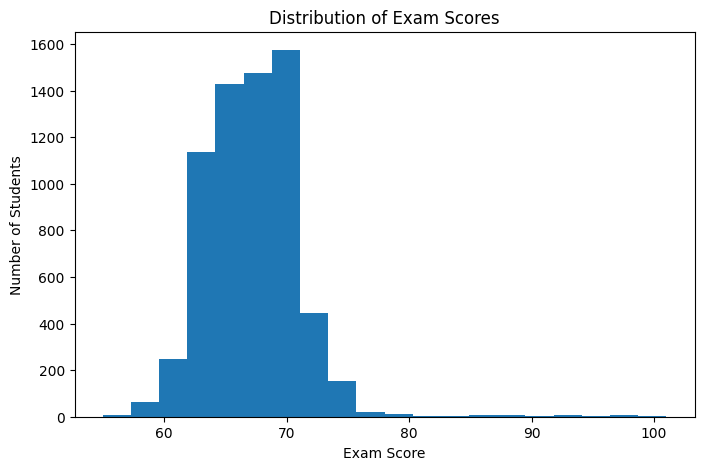

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['Exam_Score'], bins=20)
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Exam Scores')
plt.show()

Hours Studied vs Exam Score

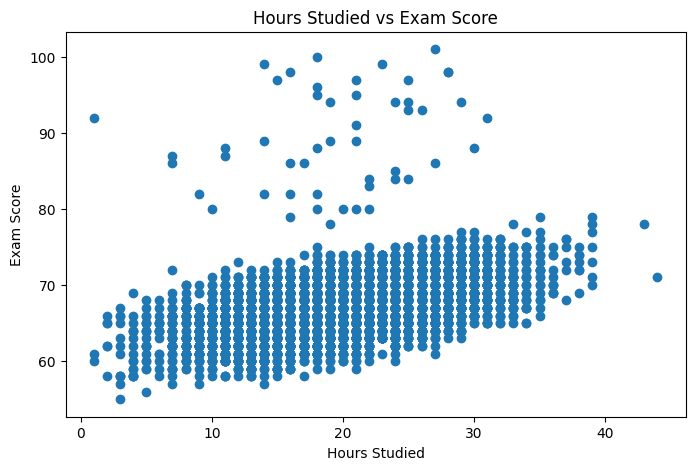

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Hours_Studied'], df['Exam_Score'])
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours Studied vs Exam Score')
plt.show()

Attendance vs Exam Score

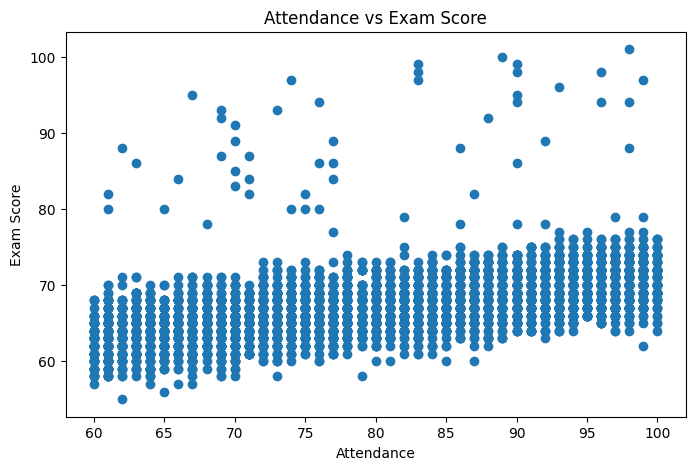

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Attendance'], df['Exam_Score'])
plt.xlabel('Attendance')
plt.ylabel('Exam Score')
plt.title('Attendance vs Exam Score')
plt.show()

Categorical feature analysis

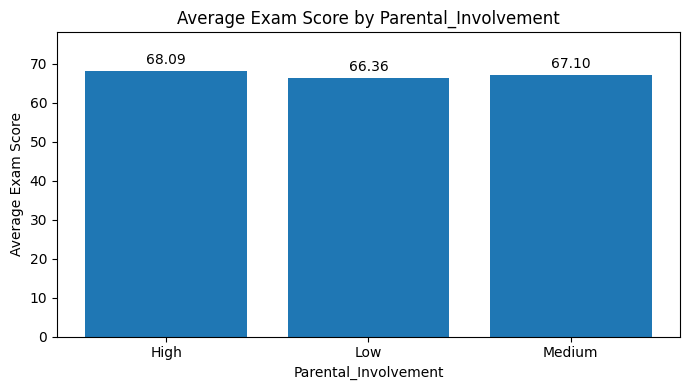

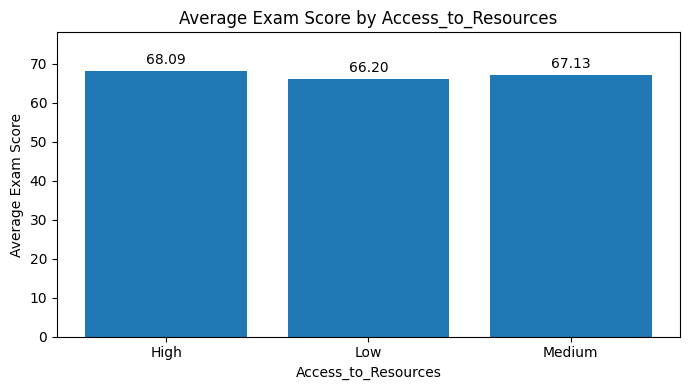

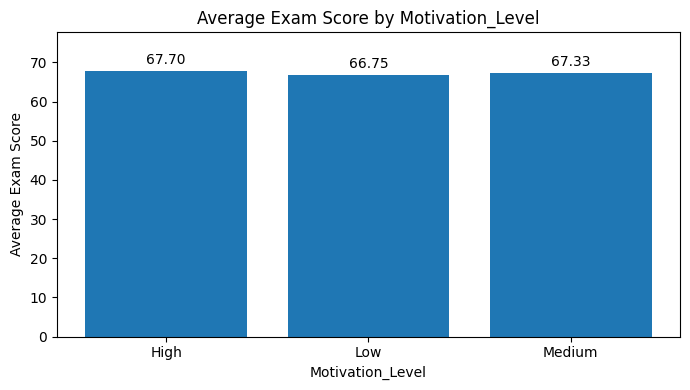

In [ ]:
import matplotlib.pyplot as plt

categorical_features = [
    'Parental_Involvement',
    'Access_to_Resources',
    'Motivation_Level'
]

for feature in categorical_features:
    averages = df.groupby(feature)['Exam_Score'].mean()

    plt.figure(figsize=(7, 4))
    bars = plt.bar(averages.index, averages.values)

    # Display the average score above each bar
    plt.bar_label(bars, fmt='%.2f', padding=3)

    plt.title(f'Average Exam Score by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Average Exam Score')
    plt.ylim(0, averages.max() + 10)
    plt.tight_layout()
    plt.show()

#STEP 7 - CORRELATION ANALYSIS

Correlation between numerical variables

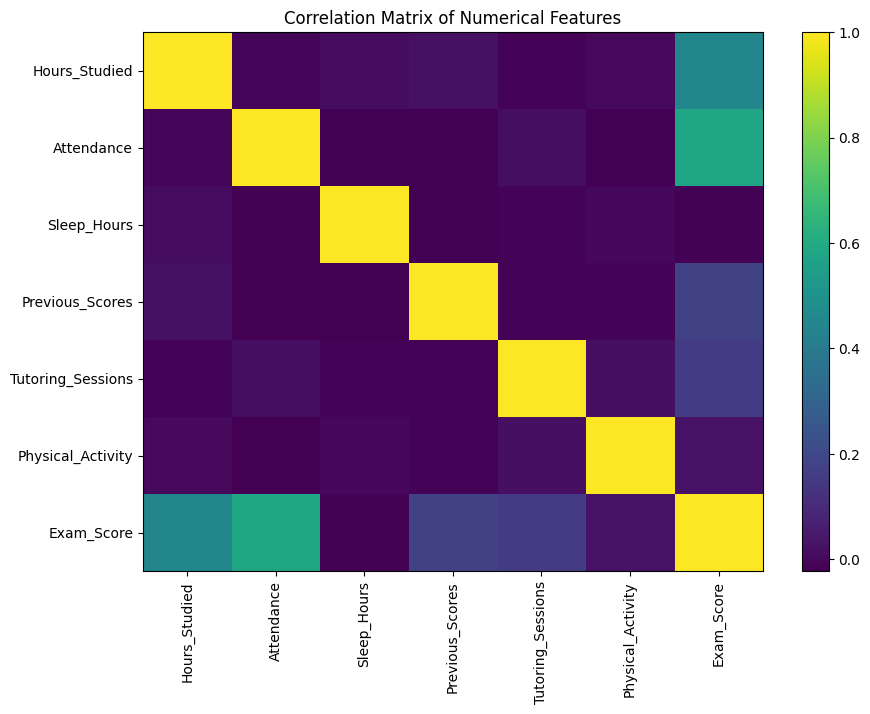

In [ ]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 7))
plt.imshow(correlation_matrix, aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()

Correlation with Exam Score

In [ ]:
exam_correlation = (
    df[numerical_columns]
    .corr()['Exam_Score']
    .sort_values(ascending=False)
)

print("Correlation with Exam Score:")
display(exam_correlation)

Correlation with Exam Score:


,Exam_Score
Exam_Score,1.000000
Attendance,0.581072
Hours_Studied,0.445455
Previous_Scores,0.175079
Tutoring_Sessions,0.156525
Physical_Activity,0.027824
Sleep_Hours,-0.017022


#STEP 8 - FEATURE AND TARGET SEPARATION

In [ ]:
features = [
    'Hours_Studied',
    'Attendance',
    'Previous_Scores',
    'Sleep_Hours',
    'Tutoring_Sessions'
]

X = df[features].copy()
y = df['Exam_Score'].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6607, 5)
Target shape: (6607,)


#STEP 9 - TRAIN-TEST SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training 80% and testing 20%\n")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training 80% and testing 20%

Training data: (5285, 5)
Testing data: (1322, 5)


#STEP 10 - DATA PREPROCESSING

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

print("Preprocessing completed successfully!\n")

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

Preprocessing completed successfully!

Training data after preprocessing: (5285, 5)
Testing data after preprocessing: (1322, 5)


#STEP 11 - MODEL BUILDING

→ Linear Regression

→ Decision Tree

→ Random Forest

→ XGBoost

→ SVM

→ Neural Network

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    ),

    'SVM': SVR(),

    'Neural Network': MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        random_state=42
    )
}

print("Six ML models created successfully!")
for name in models:
    print("-", name)

Six ML models created successfully!
- Linear Regression
- Decision Tree
- Random Forest
- XGBoost
- SVM
- Neural Network


#STEP 12 - MODEL TRAINING

In [ ]:
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_processed,
        y_train
    )

    trained_models[name] = model

    print(name, "training completed!")

print("\nAll models trained successfully!")


Training: Linear Regression
Linear Regression training completed!

Training: Decision Tree
Decision Tree training completed!

Training: Random Forest
Random Forest training completed!

Training: XGBoost
XGBoost training completed!

Training: SVM
SVM training completed!

Training: Neural Network
Neural Network training completed!

All models trained successfully!


#STEP 13 - MODEL EVALUATION

→ MAE

→ MSE

→ RMSE

→ R²

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

results = []

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([
        name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'MAE',
        'MSE',
        'RMSE',
        'R2 Score'
    ]
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.275068,5.077072,2.253236,0.640817
1,Decision Tree,1.989032,15.135212,3.890400,-0.070756
2,Random Forest,1.484425,6.402917,2.530399,0.547019
3,XGBoost,1.436444,6.116554,2.473167,0.567278
4,SVM,1.295802,5.209546,2.282443,0.631445
5,Neural Network,1.323786,5.250109,2.291312,0.628576


#STEP 14 - MODEL COMPARISION

R SQUARE COMPARISON

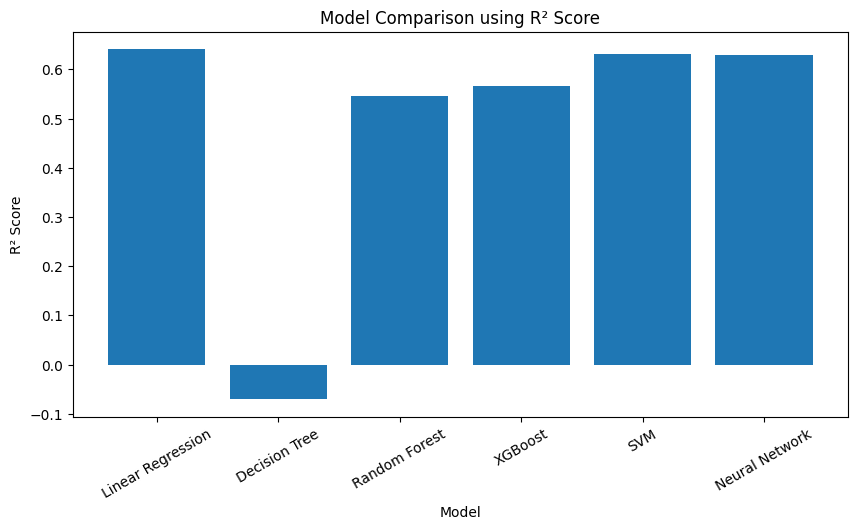

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['R2 Score']
)

plt.xlabel('Model')
plt.ylabel('R² Score')
plt.title('Model Comparison using R² Score')
plt.xticks(rotation=30)
plt.show()

RMSE Comparison

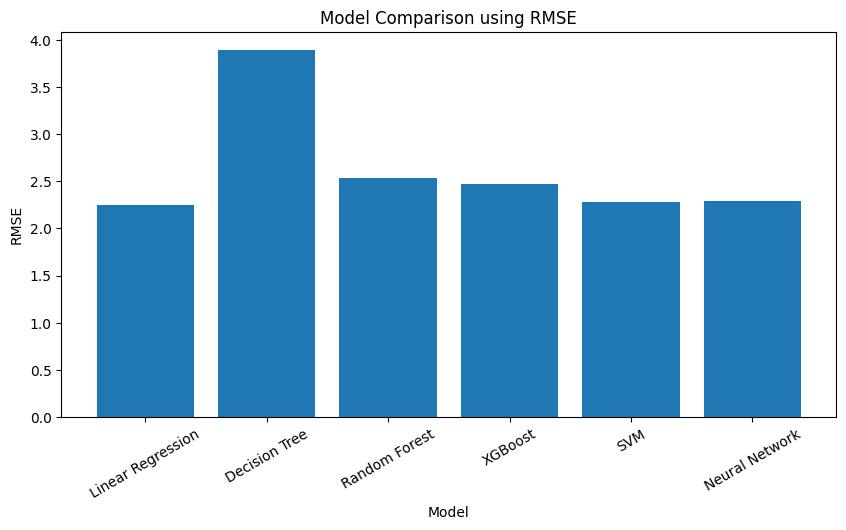

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['RMSE']
)

plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('Model Comparison using RMSE')
plt.xticks(rotation=30)
plt.show()

#STEP 15 - FEATURE IMPORTANCE

Random Forest feature importance

In [ ]:
feature_names = preprocessor.get_feature_names_out()

rf_model = trained_models['Random Forest']

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

Top 15 Important Features:


,Feature,Importance
1,num__Attendance,0.428907
0,num__Hours_Studied,0.279464
2,num__Previous_Scores,0.162445
4,num__Tutoring_Sessions,0.067312
3,num__Sleep_Hours,0.061871


Visualize top features

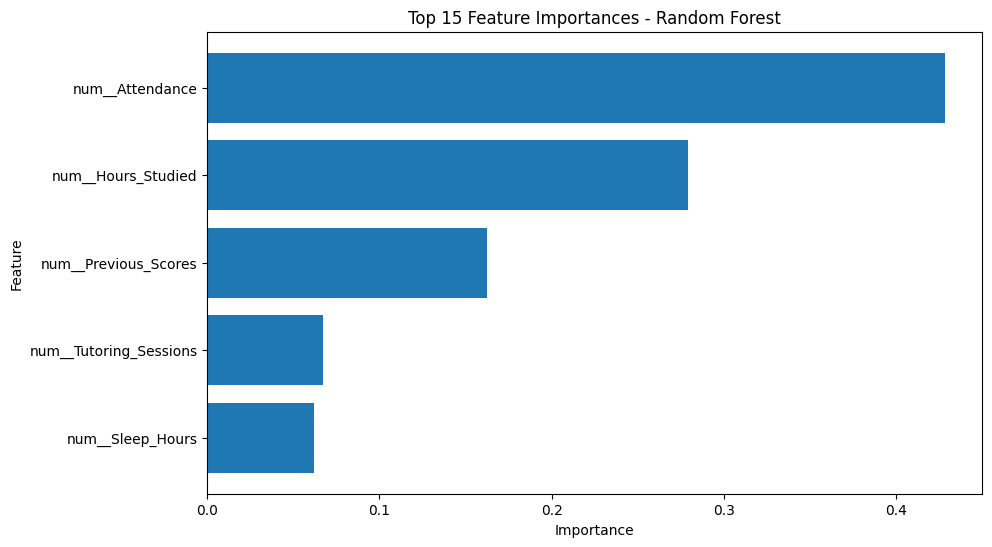

In [ ]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances - Random Forest')
plt.show()

#STEP 16 - TEST-SET RISK ANALYSIS

In [ ]:
def performance_category(score):
    if score < 60:
        return "At Risk"
    elif score < 75:
        return "Needs Improvement"
    else:
        return "On Track"

print("Performance categories defined successfully!")

risk_analysis = pd.DataFrame({
    'Actual Score': y_test.to_numpy(),
    'Predicted Score': predictions['Random Forest']
})

risk_analysis['Performance Category'] = (
    risk_analysis['Predicted Score']
    .apply(performance_category)
)

print("\nFIRST 20 TEST-SET STUDENTS")
display(risk_analysis.head(20).round(2))

print("\nPREDICTED PERFORMANCE CATEGORY COUNTS")
display(risk_analysis['Performance Category'].value_counts())

Performance categories defined successfully!

FIRST 20 TEST-SET STUDENTS


,Actual Score,Predicted Score,Performance Category
0,65,65.60,Needs Improvement
1,65,67.81,Needs Improvement
2,71,70.48,Needs Improvement
3,64,66.31,Needs Improvement
4,66,66.10,Needs Improvement
5,66,67.38,Needs Improvement
6,72,68.73,Needs Improvement
7,66,68.60,Needs Improvement
8,70,68.35,Needs Improvement
9,70,67.90,Needs Improvement



PREDICTED PERFORMANCE CATEGORY COUNTS


,count
Performance Category,
Needs Improvement,1305
On Track,14
At Risk,3


# STEP 17: ACTUAL VS PREDICTED SCORES

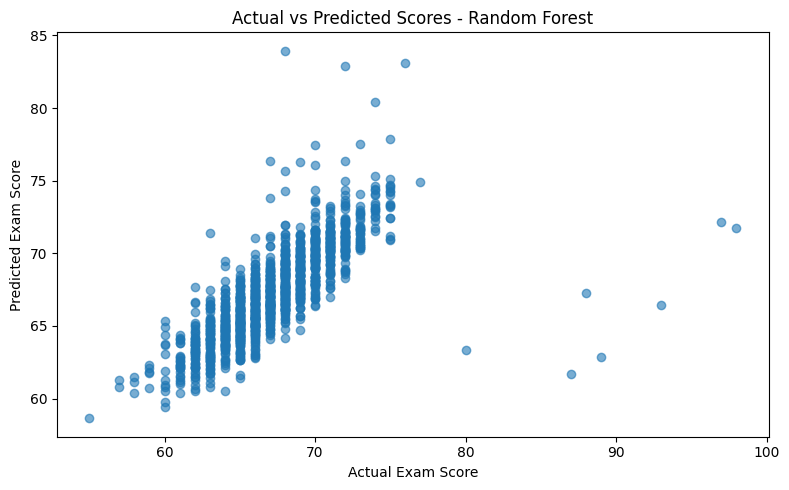

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    predictions['Random Forest'],
    alpha=0.6
)

plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Scores - Random Forest')
plt.tight_layout()
plt.show()

# STEP 18: MODEL SELECTION

In [ ]:
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(),
    'Model'
]

best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: Highest test-set R²")

Selected model: Linear Regression
Selection criterion: Highest test-set R²


# STEP 19: SAVE MODEL AND PREPROCESSOR

In [ ]:
model_path = '/content/student_performance_model.pkl'
preprocessor_path = '/content/student_preprocessor.pkl'

joblib.dump(best_model, model_path)
joblib.dump(preprocessor, preprocessor_path)

print("Model saved successfully:", model_path)
print("Preprocessor saved successfully:", preprocessor_path)

Model saved successfully: /content/student_performance_model.pkl
Preprocessor saved successfully: /content/student_preprocessor.pkl


# STEP 20: FINAL PROJECT SUMMARY

In [ ]:
print("=" * 65)
print("STUDENTS PERFORMANCE PREDICTION AND ANALYSIS USING ML")
print("=" * 65)

print("\nDATASET")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDATA QUALITY")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMODELS COMPARED")
for name in trained_models:
    print("-", name)

print("\nEVALUATION METRICS")
print("- MAE")
print("- MSE")
print("- RMSE")
print("- R2 Score")

print("\nSELECTED MODEL")
print(best_model_name)

print("\nProject completed successfully!")

STUDENTS PERFORMANCE PREDICTION AND ANALYSIS USING ML

DATASET
Rows: 6607
Columns: 20

DATA QUALITY
Missing values: 235
Duplicate rows: 0

MODELS COMPARED
- Linear Regression
- Decision Tree
- Random Forest
- XGBoost
- SVM
- Neural Network

EVALUATION METRICS
- MAE
- MSE
- RMSE
- R2 Score

SELECTED MODEL
Linear Regression

Project completed successfully!


#SAMPLE STUDENT PERFORMANCE PREDICTION WITH USER I/P

STEP 1: LOAD MODEL

In [ ]:
best_model = joblib.load(
    '/content/student_performance_model.pkl'
)

preprocessor = joblib.load(
    '/content/student_preprocessor.pkl'
)

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

Model loaded successfully!
Preprocessor loaded successfully!


STEP 2: USER INPUT

In [141]:
n = int(input("Enter the number of students: "))
student_data_list = []

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION")
print("=" * 60)

for i in range(n):
    print(f"\nEnter details for Student {i + 1}")
    student_data = {}

    for column in X.columns:
        if column in numerical_features:
            while True:
                try:
                    value = float(input(f"Enter {column}: "))

                    minimum = X[column].min()
                    maximum = X[column].max()

                    if not minimum <= value <= maximum:
                        print(
                            f"Enter a value between "
                            f"{minimum} and {maximum}."
                        )
                        continue

                    if pd.api.types.is_integer_dtype(X[column]):
                        if not value.is_integer():
                            print("Please enter a whole number.")
                            continue
                        value = int(value)

                    student_data[column] = value
                    break

                except ValueError:
                    print("Please enter a valid number.")
        else:
            valid_values = sorted(
                X[column].dropna().astype(str).unique()
            )

            print(f"\n{column} options: {valid_values}")

            while True:
                value = input(f"Enter {column}: ").strip()

                match = next(
                    (
                        option for option in valid_values
                        if option.casefold() == value.casefold()
                    ),
                    None
                )

                if match is not None:
                    student_data[column] = match
                    break

                print("Please enter one of the displayed options.")

    student_data_list.append(student_data)

sample_student = pd.DataFrame(
    student_data_list,
    columns=X.columns
)

print("\nStudent details collected successfully!")
display(sample_student)

Enter the number of students: 3
STUDENT PERFORMANCE PREDICTION

Enter details for Student 1
Enter Hours_Studied: 10
Enter Attendance: 60
Enter Previous_Scores: 50
Enter Sleep_Hours: 6
Enter Tutoring_Sessions: 0

Enter details for Student 2
Enter Hours_Studied: 20
Enter Attendance: 70
Enter Previous_Scores: 80
Enter Sleep_Hours: 7
Enter Tutoring_Sessions: 2

Enter details for Student 3
Enter Hours_Studied: 40
Enter Attendance: 100
Enter Previous_Scores: 90
Enter Sleep_Hours: 8
Enter Tutoring_Sessions: 9
Enter a value between 0 and 8.
Enter Tutoring_Sessions: 7

Student details collected successfully!


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Tutoring_Sessions
0,10,60,50,6,0
1,20,70,80,7,2
2,40,100,90,8,7


STEP 3: PREPROCESS INPUT

In [142]:
sample_processed = preprocessor.transform(sample_student)

print("Student data preprocessed successfully!")
print("Processed shape:", sample_processed.shape)

Student data preprocessed successfully!
Processed shape: (3, 5)


STEP 4: PREDICT SCORE

In [144]:
sample_predictions = {}

print("=" * 50)
print("PREDICTED EXAM SCORES")
print("=" * 50)

for name, model in trained_models.items():
    scores = model.predict(sample_processed)
    sample_predictions[name] = scores

    print(f"\n{name}:")
    for i, score in enumerate(scores, start=1):
        print(f"Student {i}: {score:.2f}")

PREDICTED EXAM SCORES

Linear Regression:
Student 1: 58.45
Student 2: 65.76
Student 3: 80.51

Decision Tree:
Student 1: 60.00
Student 2: 65.00
Student 3: 79.00

Random Forest:
Student 1: 59.87
Student 2: 65.90
Student 3: 84.03

XGBoost:
Student 1: 59.28
Student 2: 65.50
Student 3: 82.39

SVM:
Student 1: 60.40
Student 2: 65.73
Student 3: 70.29

Neural Network:
Student 1: 59.82
Student 2: 65.36
Student 3: 86.25


STEP 5: FINAL PREDICTION

In [145]:
predicted_scores = best_model.predict(sample_processed)

categories = [
    performance_category(score)
    for score in predicted_scores
]

print("=" * 50)
print("FINAL PREDICTION RESULTS")
print("=" * 50)

print("Selected model:", best_model_name)

for i, (score, category) in enumerate(
    zip(predicted_scores, categories), start=1
):
    print(f"\nStudent {i}")
    print("Predicted exam score:", round(score, 2))
    print("Performance category:", category)

FINAL PREDICTION RESULTS
Selected model: Linear Regression

Student 1
Predicted exam score: 58.45
Performance category: At Risk

Student 2
Predicted exam score: 65.76
Performance category: Needs Improvement

Student 3
Predicted exam score: 80.51
Performance category: On Track
